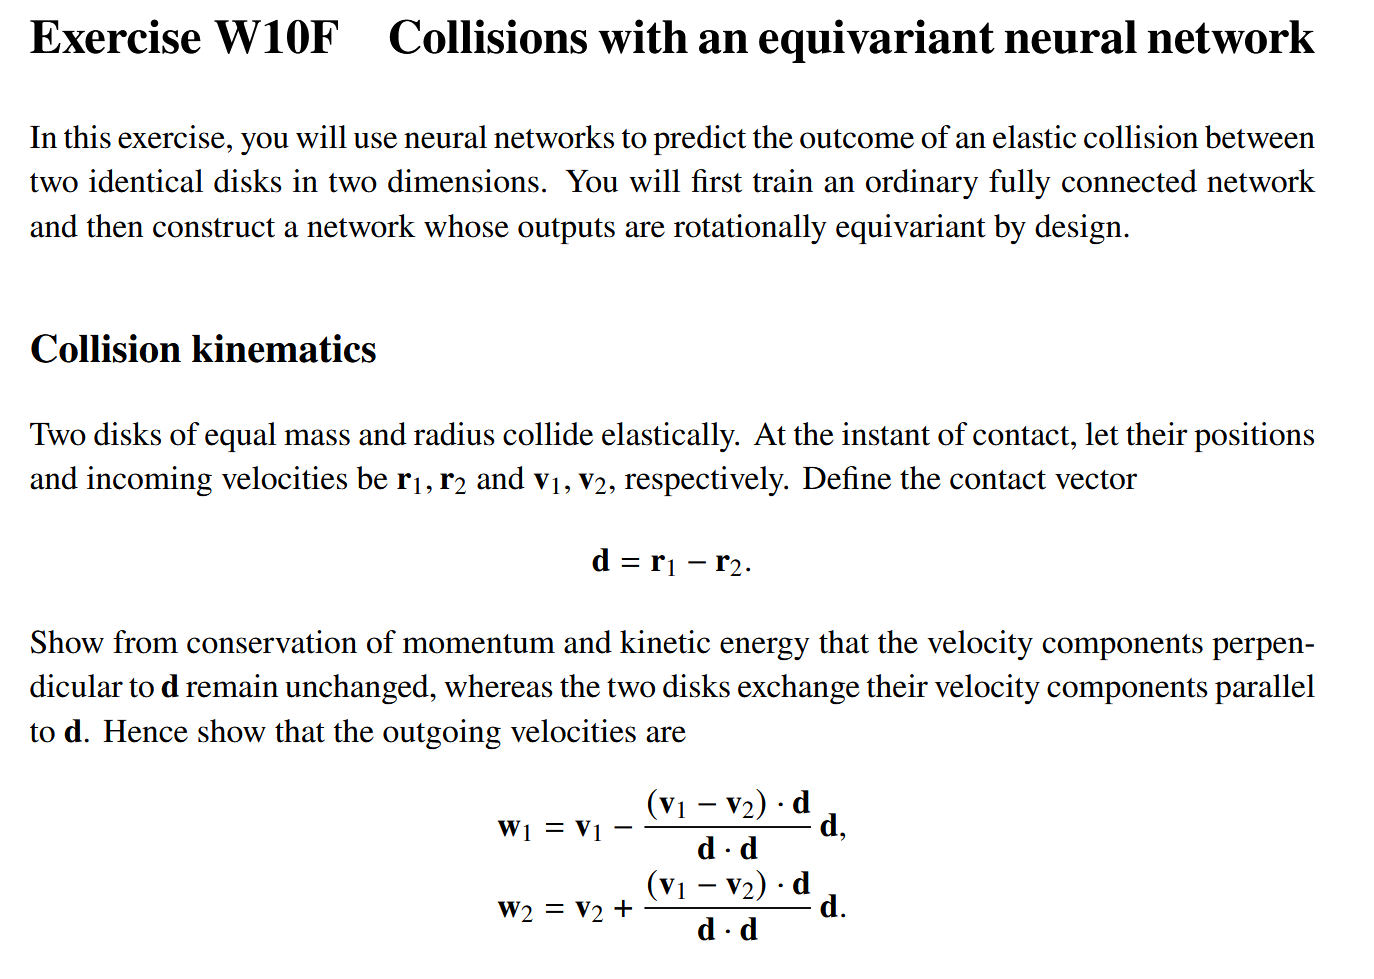

During an elastic collision between two smooth identical disks, the impulsive contact force acts exclusively along the line connecting their centers, which is defined by the contact vector $\mathbf{d} = \mathbf{r}_1 - \mathbf{r}_2$. Because no forces act perpendicular to this axis, there is no change in momentum in the perpendicular direction for either disk. Consequently, the velocity components perpendicular to $\mathbf{d}$ remain completely unchanged.

This reduces the interaction to a one-dimensional elastic collision along the parallel axis $\mathbf{d}$. For two disks of equal mass $m$, conservation of momentum and kinetic energy along this axis are given by:

1. **Momentum:** $m v_{1\parallel} + m v_{2\parallel} = m w_{1\parallel} + m w_{2\parallel} \implies v_{1\parallel} + v_{2\parallel} = w_{1\parallel} + w_{2\parallel}$
2. **Kinetic Energy:** $\frac{1}{2}m v_{1\parallel}^2 + \frac{1}{2}m v_{2\parallel}^2 = \frac{1}{2}m w_{1\parallel}^2 + \frac{1}{2}m w_{2\parallel}^2 \implies v_{1\parallel}^2 + v_{2\parallel}^2 = w_{1\parallel}^2 + w_{2\parallel}^2$

Solving this standard system of equations for identical masses dictates that the particles perfectly exchange their velocities along the collision axis. Therefore, the outgoing parallel components become $w_{1\parallel} = v_{2\parallel}$ and $w_{2\parallel} = v_{1\parallel}$.

To express this vectorially, we find the parallel component of the relative velocity $\mathbf{v}_1 - \mathbf{v}_2$ by projecting it onto $\mathbf{d}$:

$$\Delta\mathbf{v}_\parallel = \frac{(\mathbf{v}_1 - \mathbf{v}_2) \cdot \mathbf{d}}{\mathbf{d} \cdot \mathbf{d}} \mathbf{d}$$

Since the disks exchange their parallel velocities, disk 1 loses its relative parallel velocity component and disk 2 gains it. Subtracting this projection from disk 1's initial velocity and adding it to disk 2's initial velocity yields the final outgoing velocities:

$$\mathbf{w}_1 = \mathbf{v}_1 - \frac{(\mathbf{v}_1 - \mathbf{v}_2) \cdot \mathbf{d}}{\mathbf{d} \cdot \mathbf{d}} \mathbf{d}$$



$$\mathbf{w}_2 = \mathbf{v}_2 + \frac{(\mathbf{v}_1 - \mathbf{v}_2) \cdot \mathbf{d}}{\mathbf{d} \cdot \mathbf{d}} \mathbf{d}$$

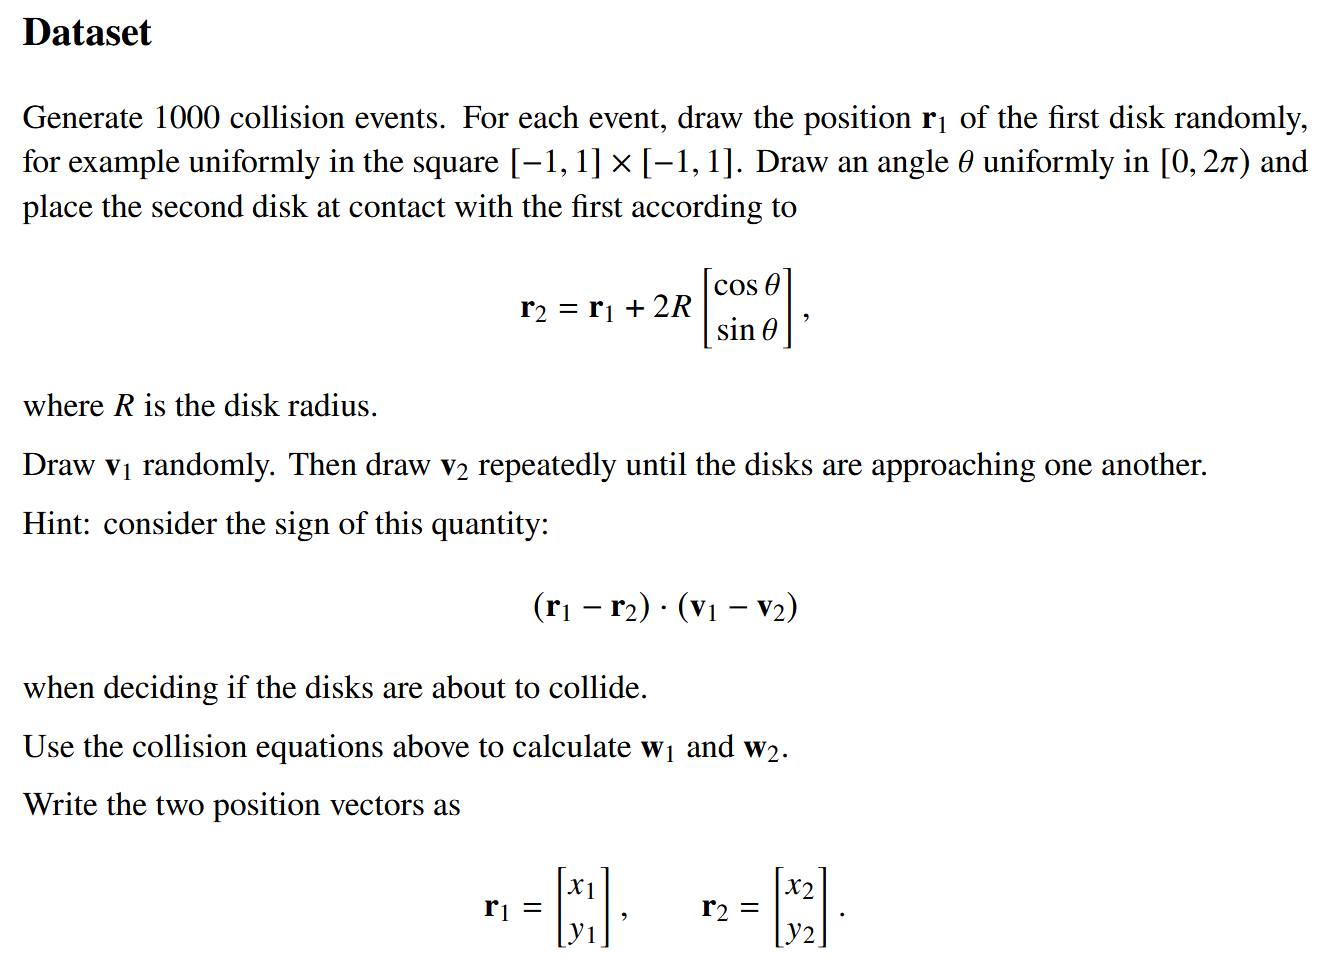
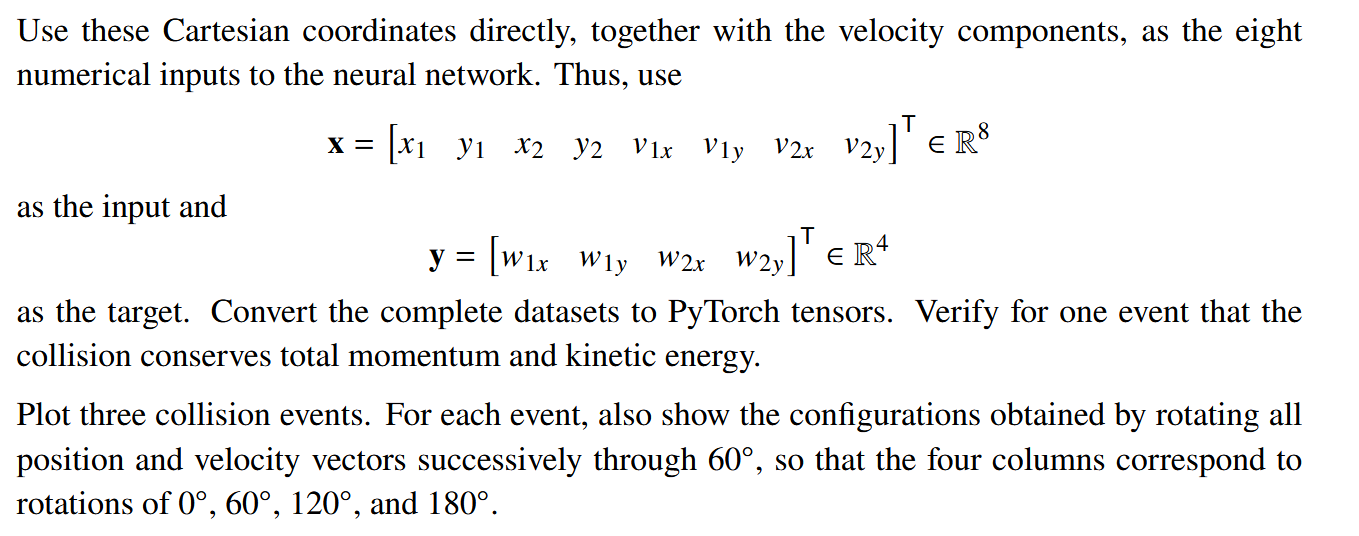

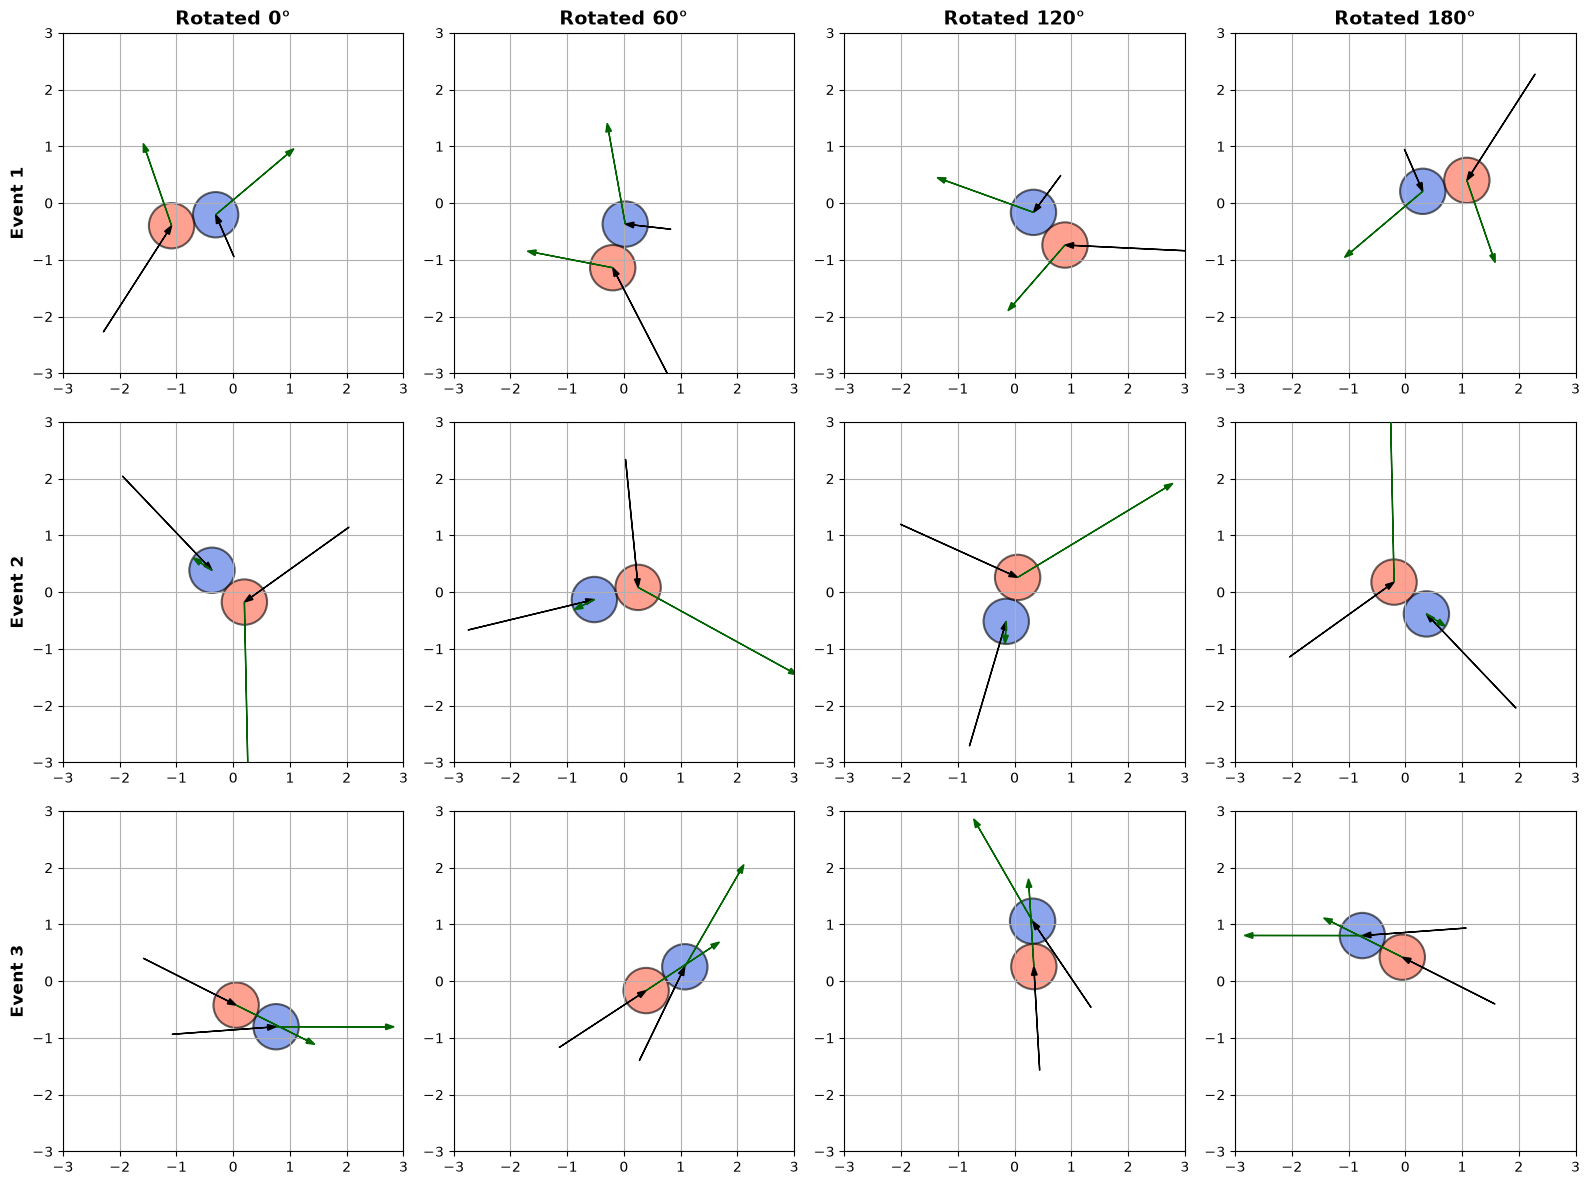

In [15]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt
import numpy as np

# Fix 1: Set both NumPy and PyTorch seeds to ensure true reproducibility
np.random.seed(1)
torch.manual_seed(1)

N = 1000
R = 0.4 

X_data = np.zeros((N, 8))
Y_data = np.zeros((N, 4))

for i in range(N):
    r1 = np.random.uniform(-1, 1, 2)
    
    theta = np.random.uniform(0, 2*np.pi)
    r2 = r1 + 2 * R * np.array([np.cos(theta), np.sin(theta)])
    
    v1 = np.random.uniform(-2, 2, 2)
    while True:
        v2 = np.random.uniform(-2, 2, 2)
        if np.dot(r1 - r2, v1 - v2) < 0:
            break
            
    d = r1 - r2
    dot_prod = np.dot(v1 - v2, d)
    mag_sq = np.dot(d, d)
    
    w1 = v1 - (dot_prod / mag_sq) * d
    w2 = v2 + (dot_prod / mag_sq) * d
    
    X_data[i] = [r1[0], r1[1], r2[0], r2[1], v1[0], v1[1], v2[0], v2[1]]
    Y_data[i] = [w1[0], w1[1], w2[0], w2[1]]

X_tensor = torch.tensor(X_data, dtype=torch.float32)
Y_tensor = torch.tensor(Y_data, dtype=torch.float32)

fig, axes = plt.subplots(3, 4, figsize=(16, 12))
    
for row, ev_idx in enumerate([1, 2, 3]):
    r1_orig = X_data[ev_idx, 0:2]
    r2_orig = X_data[ev_idx, 2:4]
    v1_orig = X_data[ev_idx, 4:6]
    v2_orig = X_data[ev_idx, 6:8]
    w1_orig = Y_data[ev_idx, 0:2]
    w2_orig = Y_data[ev_idx, 2:4]
    
    for col, angle_deg in enumerate([0, 60, 120, 180]):
        ax = axes[row, col]
        angle_rad = np.radians(angle_deg)
        
        rot_mat = np.array([
            [np.cos(angle_rad), -np.sin(angle_rad)],
            [np.sin(angle_rad),  np.cos(angle_rad)]
        ])
        
        r1_rot = rot_mat @ r1_orig
        r2_rot = rot_mat @ r2_orig
        v1_rot = rot_mat @ v1_orig
        v2_rot = rot_mat @ v2_orig
        w1_rot = rot_mat @ w1_orig
        w2_rot = rot_mat @ w2_orig
        
        circle1 = plt.Circle(r1_rot, R, color='royalblue', alpha=0.6, ec='black', lw=1.5)
        circle2 = plt.Circle(r2_rot, R, color='tomato', alpha=0.6, ec='black', lw=1.5)
        ax.add_patch(circle1)
        ax.add_patch(circle2)
        
        ax.arrow(*(r1_rot - v1_rot), *v1_rot, head_width=0.1, color='black', length_includes_head=True, zorder=3)
        ax.arrow(*(r2_rot - v2_rot), *v2_rot, head_width=0.1, color='black', length_includes_head=True, zorder=3)
        
        ax.arrow(*r1_rot, *w1_rot, head_width=0.1, color='darkgreen', length_includes_head=True, zorder=3)
        ax.arrow(*r2_rot, *w2_rot, head_width=0.1, color='darkgreen', length_includes_head=True, zorder=3)
        
        ax.set_aspect('equal')
        ax.set_xlim(-3, 3)
        ax.set_ylim(-3, 3)
        ax.grid(True)
        
        if row == 0:
            ax.set_title(f'Rotated {angle_deg}°', fontsize=14, fontweight='bold')
        if col == 0:
            ax.set_ylabel(f'Event {row+1}', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

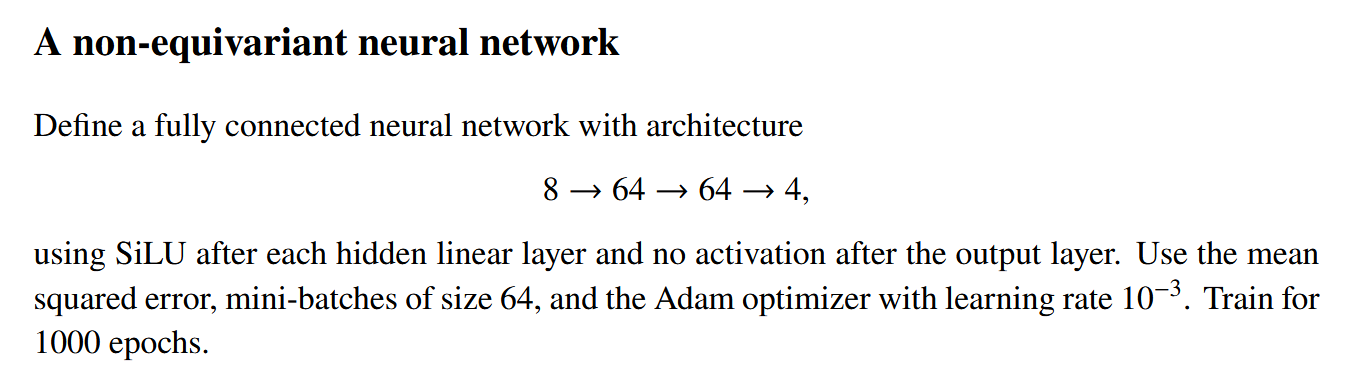
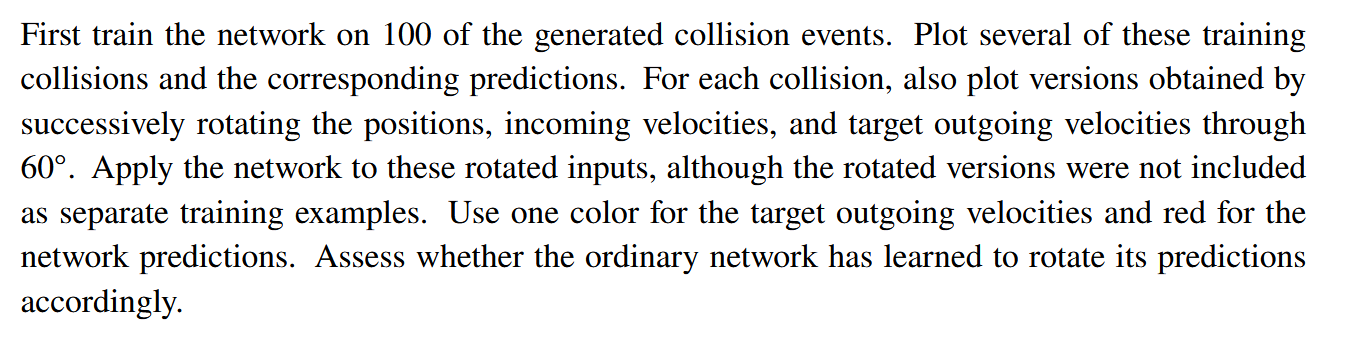

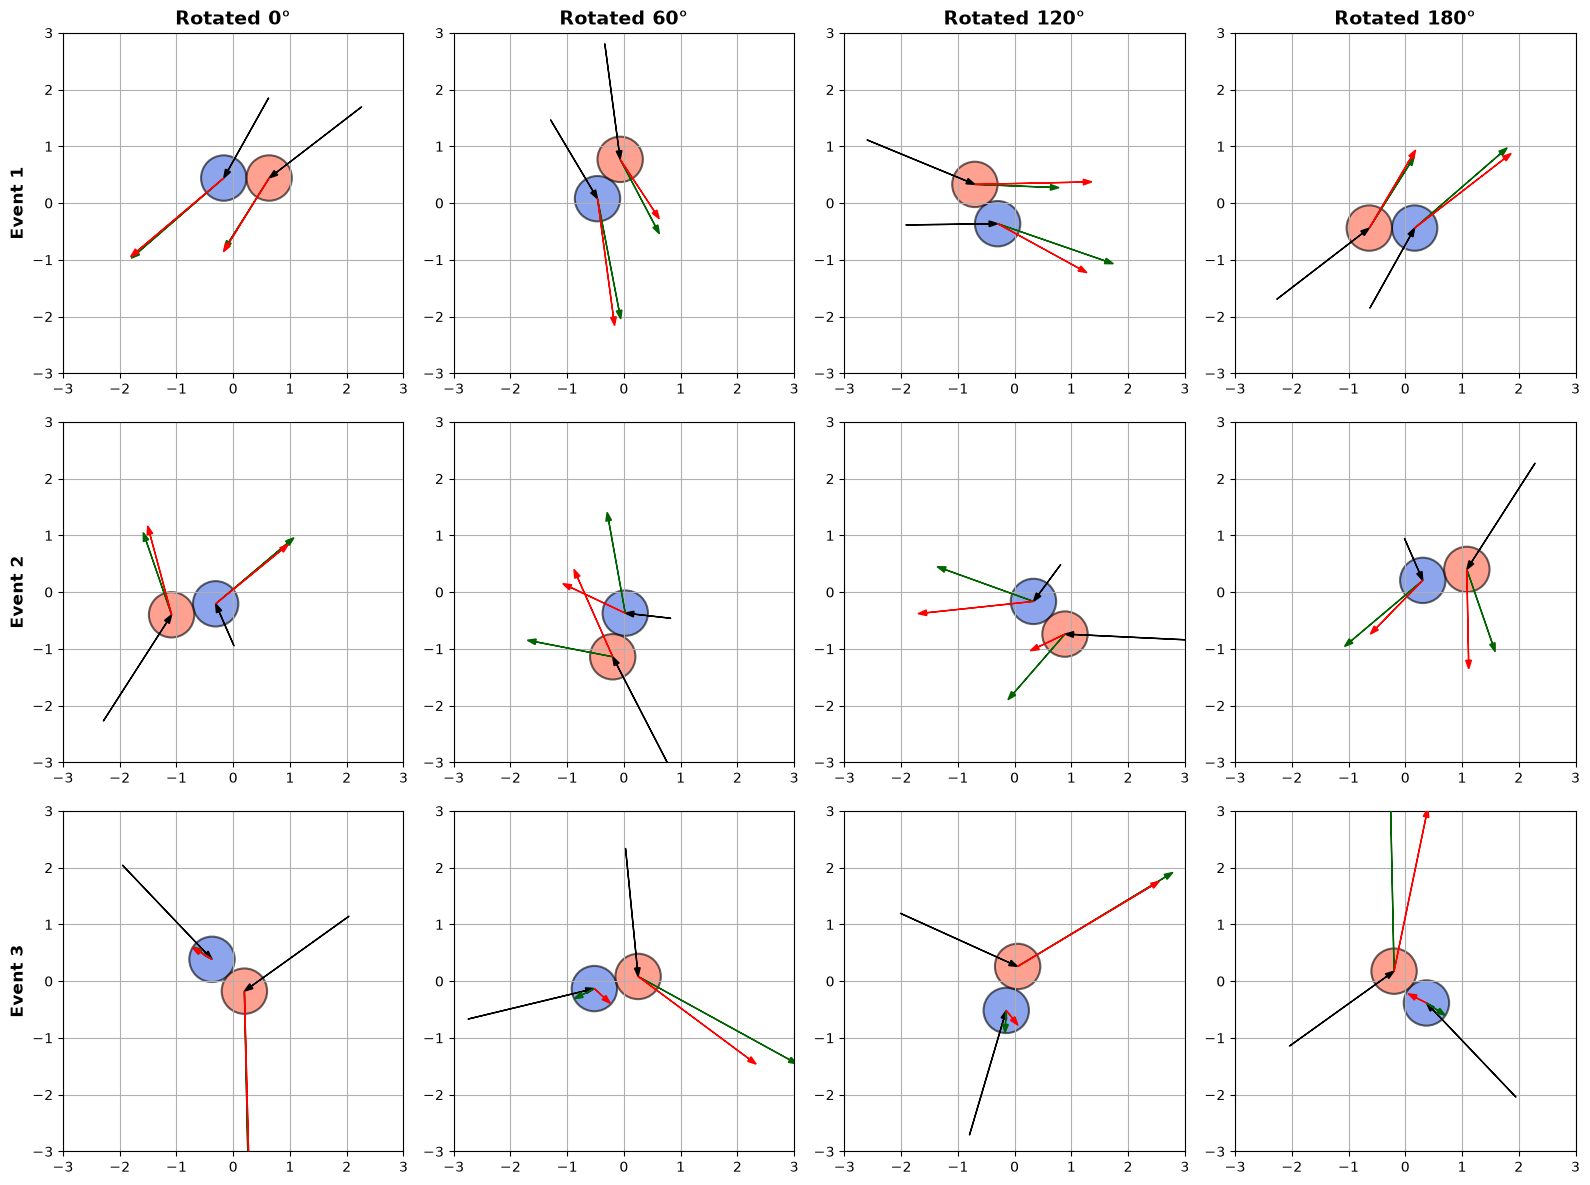

In [ ]:
class NonEquivariantNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(8, 64),
            nn.SiLU(),
            nn.Linear(64, 64),
            nn.SiLU(),
            nn.Linear(64, 4)
        )

    def forward(self, x):
        return self.net(x)

def plot_collision_predictions(model, X_data, Y_data, events=[0, 1, 2], angles=[0, 60, 120, 180], R=0.4):
    fig, axes = plt.subplots(len(events), len(angles), figsize=(16, 12))
    
    for row, ev_idx in enumerate(events):
        r1_orig = X_data[ev_idx, 0:2]
        r2_orig = X_data[ev_idx, 2:4]
        v1_orig = X_data[ev_idx, 4:6]
        v2_orig = X_data[ev_idx, 6:8]
        w1_orig = Y_data[ev_idx, 0:2]
        w2_orig = Y_data[ev_idx, 2:4]
        
        for col, angle_deg in enumerate(angles):
            ax = axes[row, col]
            angle_rad = np.radians(angle_deg)
            
            rot_mat = np.array([
                [np.cos(angle_rad), -np.sin(angle_rad)],
                [np.sin(angle_rad),  np.cos(angle_rad)]
            ])
            
            r1_rot = rot_mat @ r1_orig
            r2_rot = rot_mat @ r2_orig
            v1_rot = rot_mat @ v1_orig
            v2_rot = rot_mat @ v2_orig
            w1_rot = rot_mat @ w1_orig
            w2_rot = rot_mat @ w2_orig
            
            x_rot_tensor = torch.tensor([*r1_rot, *r2_rot, *v1_rot, *v2_rot], dtype=torch.float32)
            with torch.no_grad():
                y_pred = model(x_rot_tensor.unsqueeze(0)).squeeze(0).numpy()
                
            w1_pred = y_pred[0:2]
            w2_pred = y_pred[2:4]
            
            circle1 = plt.Circle(r1_rot, R, color='royalblue', alpha=0.6, ec='black', lw=1.5)
            circle2 = plt.Circle(r2_rot, R, color='tomato', alpha=0.6, ec='black', lw=1.5)
            ax.add_patch(circle1)
            ax.add_patch(circle2)
            
            ax.arrow(*(r1_rot - v1_rot), *v1_rot, head_width=0.1, color='black', length_includes_head=True, zorder=3)
            ax.arrow(*(r2_rot - v2_rot), *v2_rot, head_width=0.1, color='black', length_includes_head=True, zorder=3)
            
            ax.arrow(*r1_rot, *w1_rot, head_width=0.1, color='darkgreen', length_includes_head=True, zorder=3)
            ax.arrow(*r2_rot, *w2_rot, head_width=0.1, color='darkgreen', length_includes_head=True, zorder=3)
            
            ax.arrow(*r1_rot, *w1_pred, head_width=0.1, color='red', length_includes_head=True, zorder=4)
            ax.arrow(*r2_rot, *w2_pred, head_width=0.1, color='red', length_includes_head=True, zorder=4)
            
            ax.set_aspect('equal')
            ax.set_xlim(-3, 3)
            ax.set_ylim(-3, 3)
            ax.grid(True)
            
            if row == 0:
                ax.set_title(f'Rotated {angle_deg}°', fontsize=14, fontweight='bold')
            if col == 0:
                ax.set_ylabel(f'Event {row+1}', fontsize=12, fontweight='bold')

    plt.tight_layout()
    plt.show()

# Use the first 100 events for training
X_train = X_tensor[:100]
Y_train = Y_tensor[:100]

dataset = TensorDataset(X_train, Y_train)
dataloader = DataLoader(dataset, batch_size=64, shuffle=True)

model = NonEquivariantNet()
optimizer = optim.Adam(model.parameters(), lr=1e-3)
loss_fn = nn.MSELoss()

for epoch in range(1000):
    for batch_x, batch_y in dataloader:
        optimizer.zero_grad()
        y_pred = model(batch_x)
        loss = loss_fn(y_pred, batch_y)
        loss.backward()
        optimizer.step() 

plot_collision_predictions(model, X_data, Y_data)

## **Explanation**
The fully connected neural network is defined with an architecture of $8 \rightarrow 64 \rightarrow 64 \rightarrow 4$. The model applies the `SiLU` activation function after each hidden layer and omits activation on the output layer. It trains on the first 100 generated collision events using mean squared error loss, mini-batches of size 64, and the Adam optimizer with a learning rate of $10^{-3}$ for 1000 epochs. The visualization logic applies the trained model to input states successively rotated by $60^\circ$, plotting the true target outgoing velocities in dark green and the network's predictions in red.

When examining the output, you will see that the ordinary network fails entirely to rotate its predictions accordingly. In the unrotated $0^\circ$ column (the training data), the red prediction arrows perfectly overlap the green target arrows. However, as the initial state is rotated into new configurations ($60^\circ, 120^\circ, 180^\circ$) that the network did not see during training, the red arrows point in completely incorrect, arbitrary directions. Standard fully connected neural networks lack inherent rotational equivariance; they interpret rotated coordinate values as completely novel features rather than a geometric rotation of a known scenario.

It makes perfect sense. To a standard fully connected neural network, a rotated collision isn't the same event viewed from a different angle—it is an entirely new, unrecognizable set of random numbers.

When you rotate the physical system by $60^\circ$, the underlying physics remains identical, but every single Cartesian coordinate and velocity component in your input array changes drastically. Because standard neural networks treat the input simply as a flat list of eight independent numbers, the network has no inherent spatial awareness. It doesn't know what a "vector" or an "angle" is.

The network hasn't actually learned the **laws of conservation of momentum and energy**; it has merely memorized a highly specific mathematical curve that fits the localized numerical distribution of your unrotated training data. The moment you feed it numbers outside that specific numerical distribution, the predictions fall apart.

This is exactly why the exercise is leading you toward building an **equivariant neural network**. To fix this limitation, you have to design an architecture that forces the network to process the inputs as true geometric vectors rather than disconnected scalars, guaranteeing that if you rotate the inputs by a certain angle, the predicted outputs automatically rotate by that exact same angle.

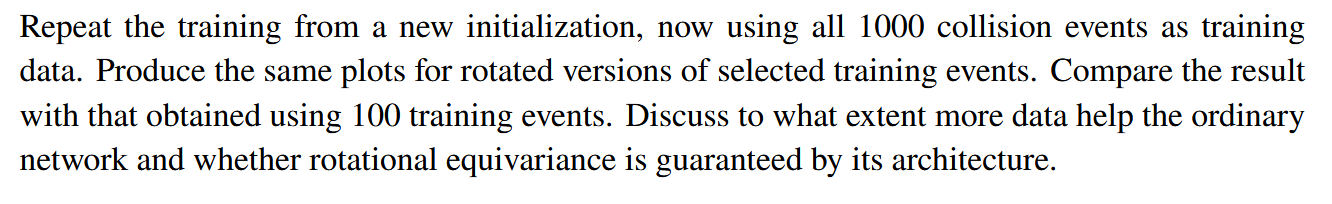

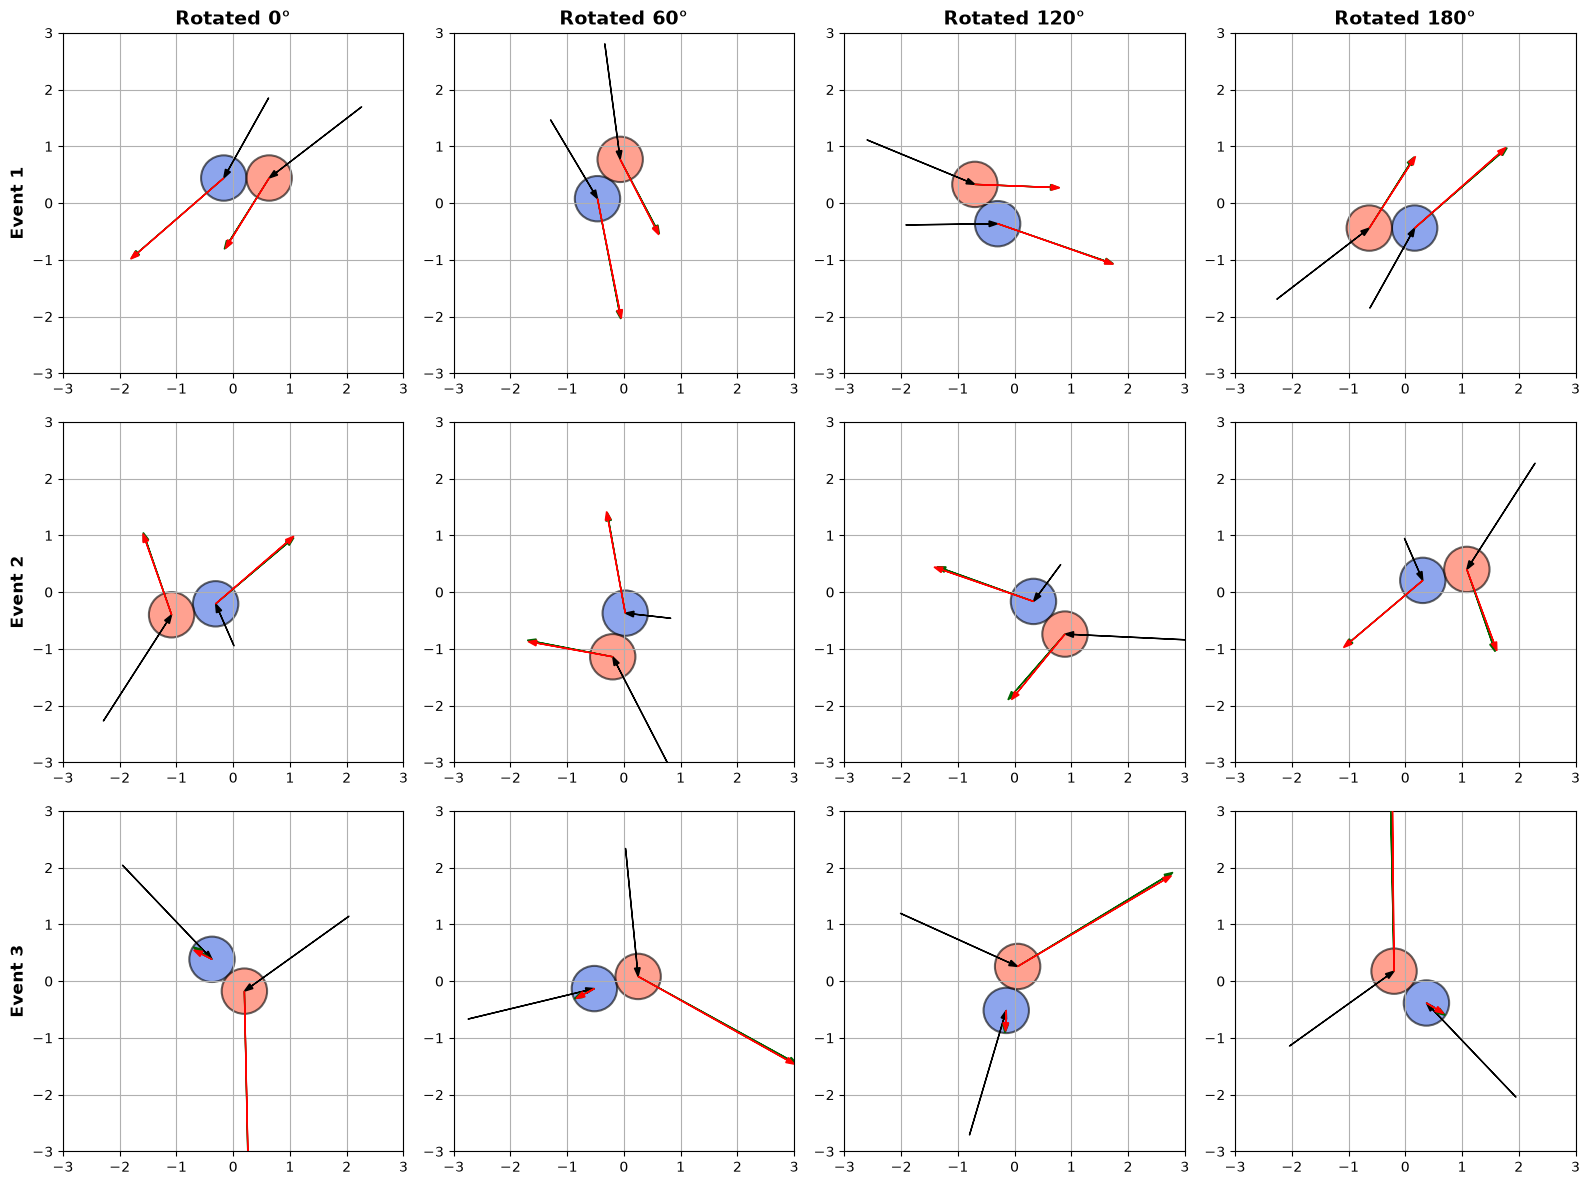

In [ ]:
# Use all events for training
X_train = X_tensor
Y_train = Y_tensor

dataset = TensorDataset(X_train, Y_train)
dataloader = DataLoader(dataset, batch_size=64, shuffle=True)

model = NonEquivariantNet()
optimizer = optim.Adam(model.parameters(), lr=1e-3)
loss_fn = nn.MSELoss()

for epoch in range(1000):
    for batch_x, batch_y in dataloader:
        optimizer.zero_grad()
        y_pred = model(batch_x)
        loss = loss_fn(y_pred, batch_y)
        loss.backward()
        optimizer.step()

plot_collision_predictions(model, X_data, Y_data)

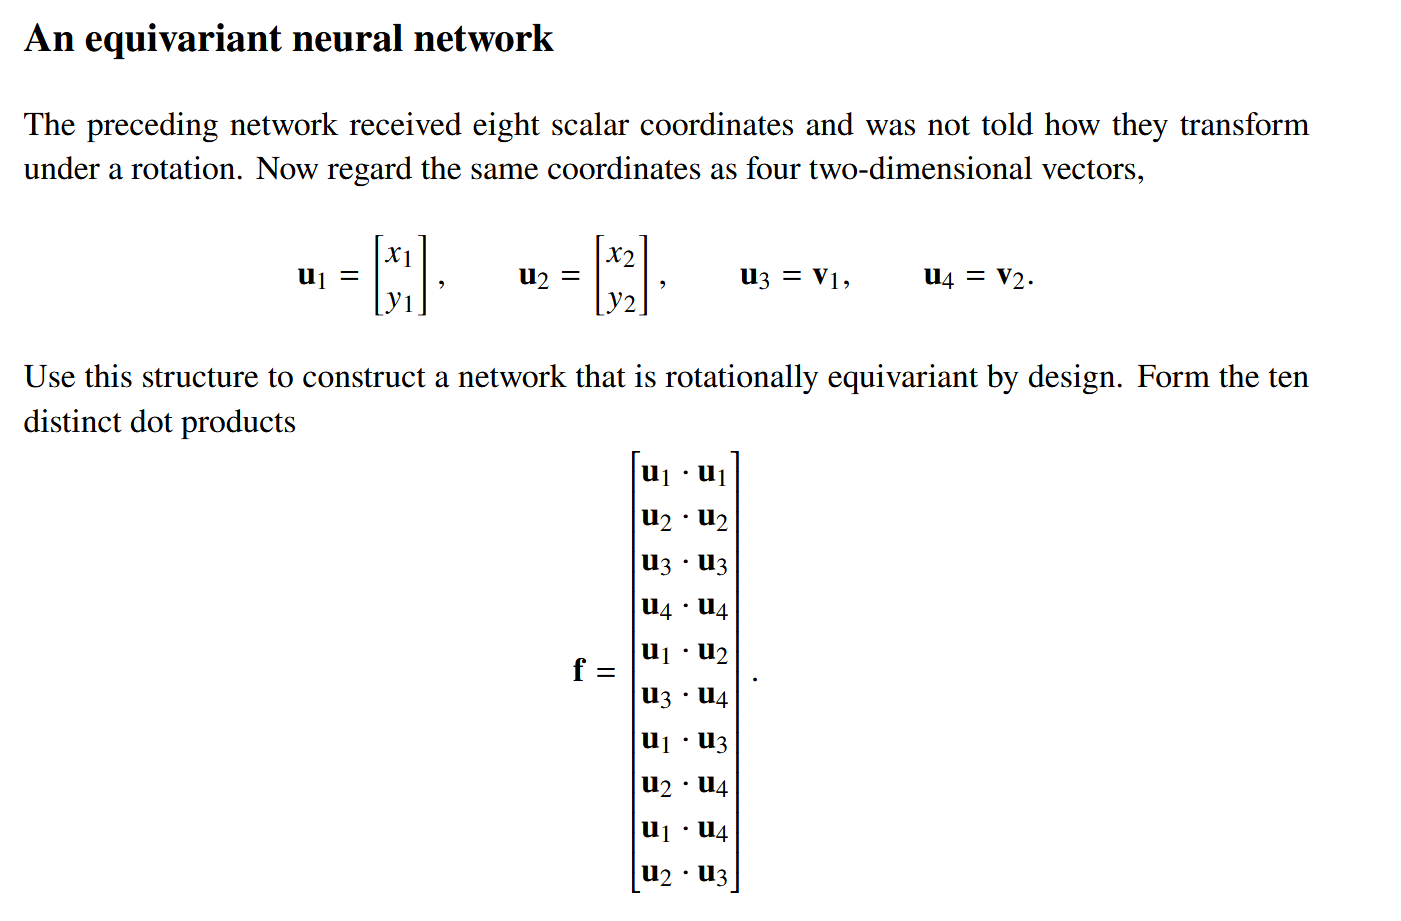
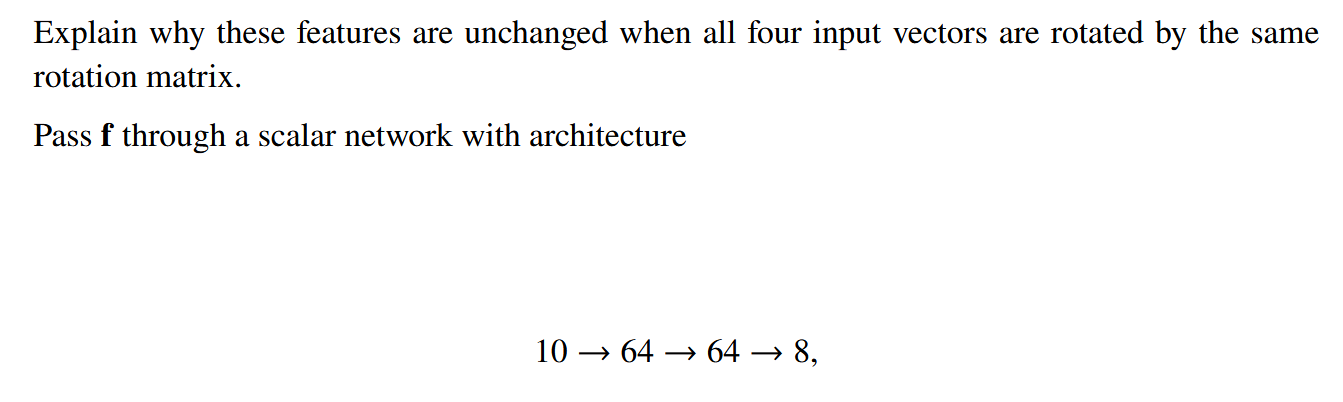
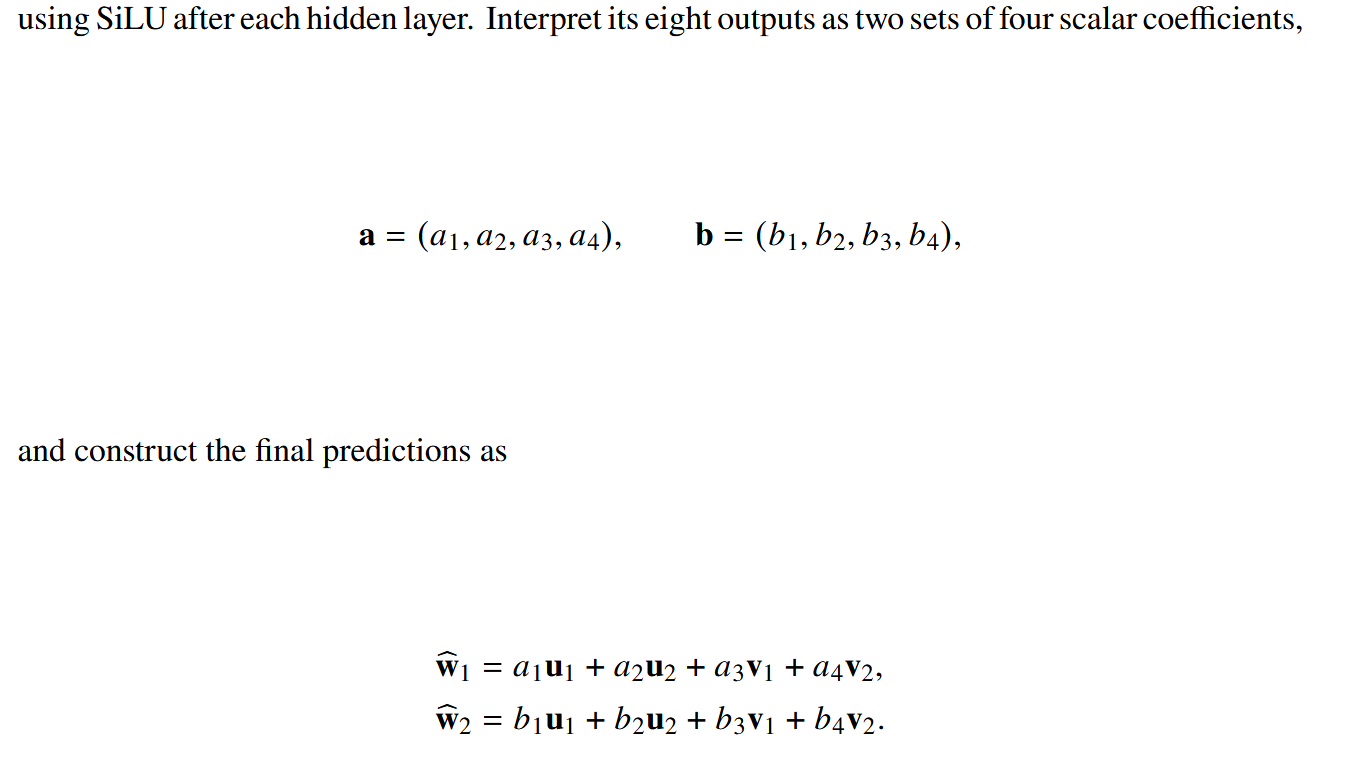
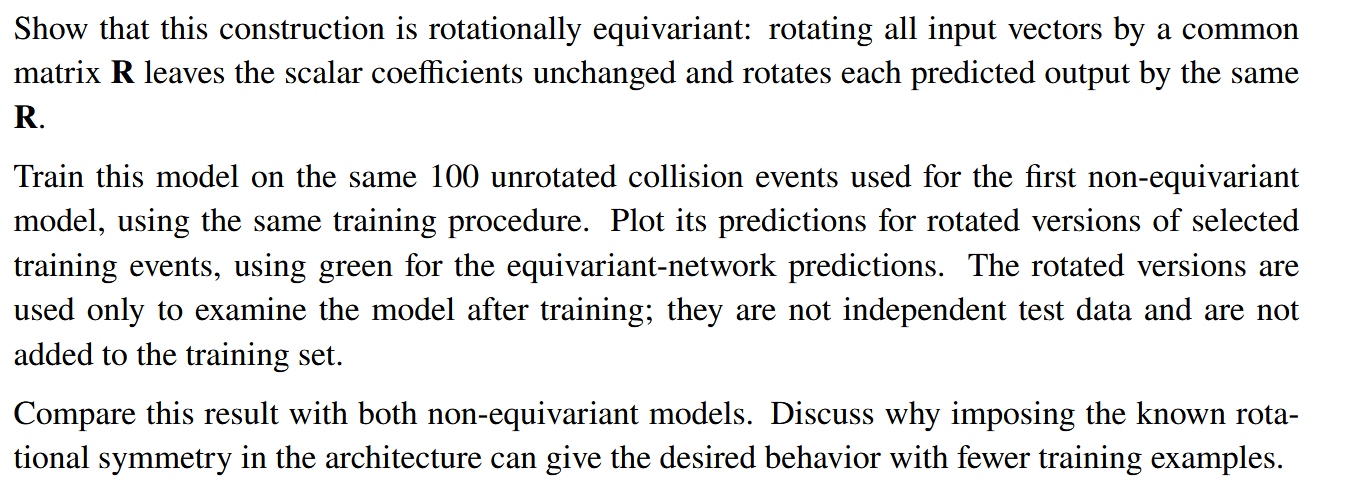

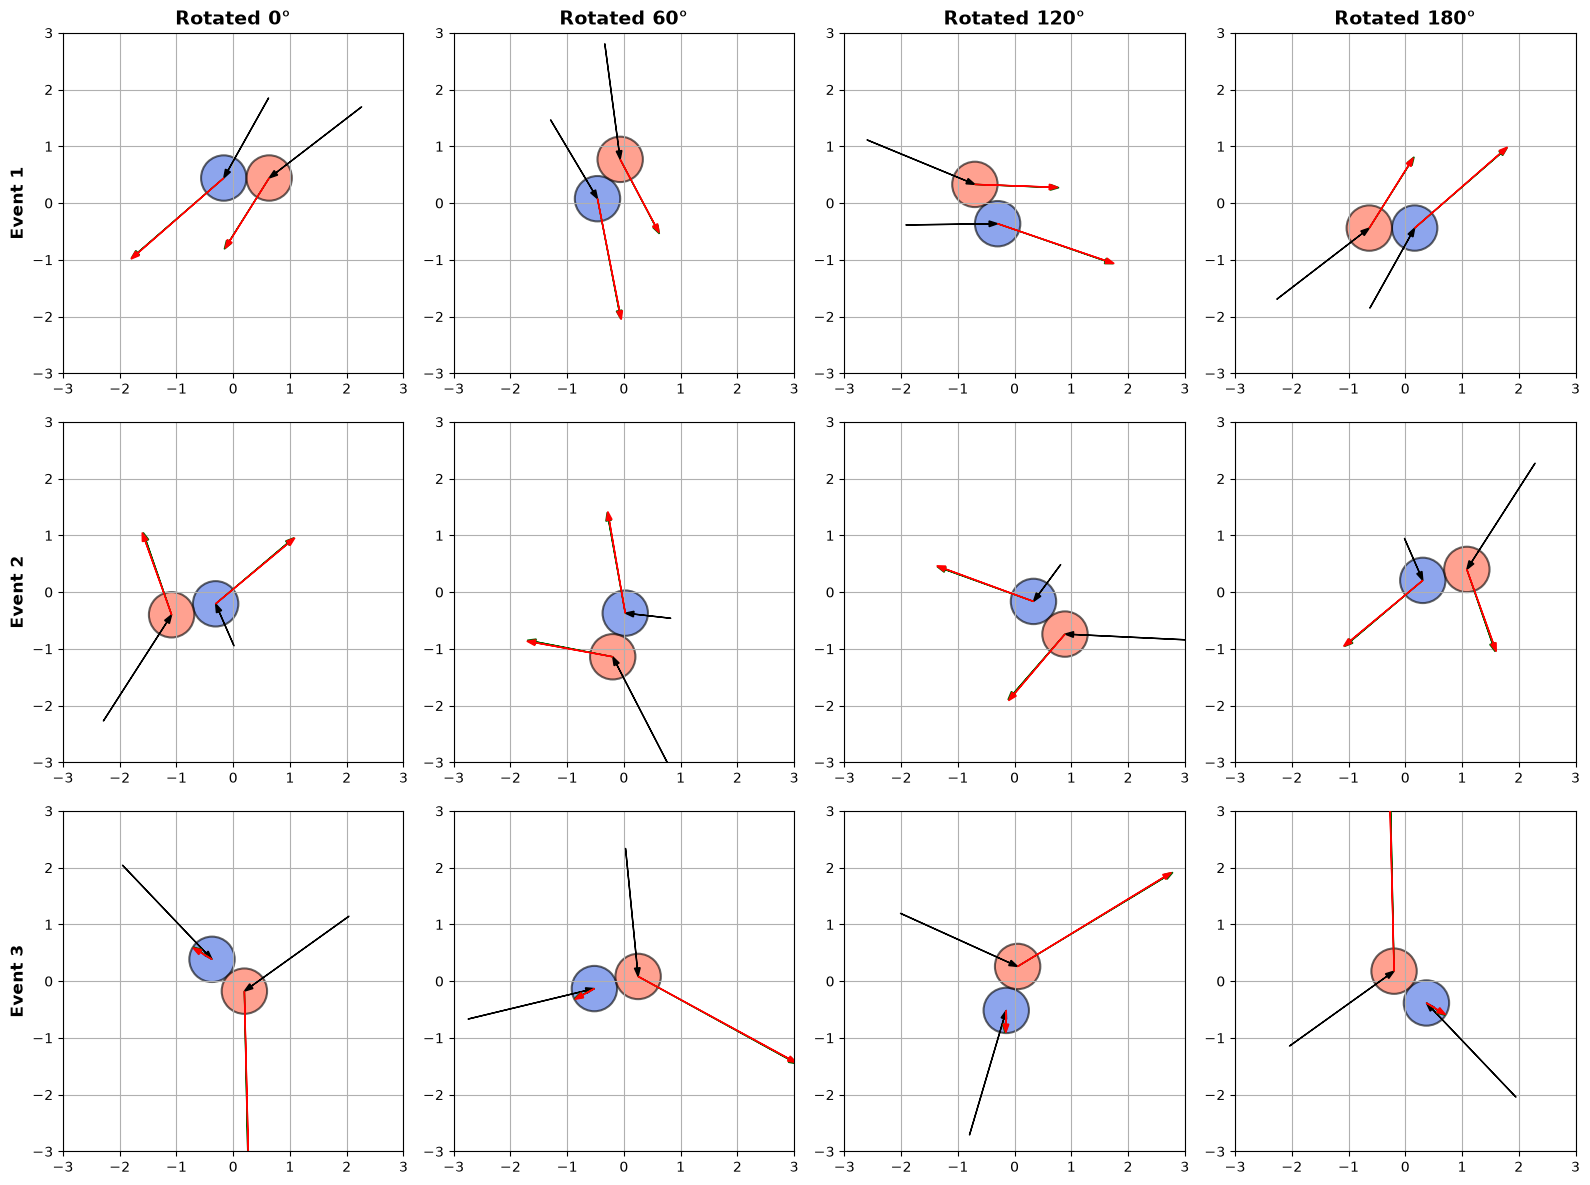

In [19]:
class EquivariantNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.scalar_net = nn.Sequential(
            nn.Linear(10, 64),
            nn.SiLU(),
            nn.Linear(64, 64),
            nn.SiLU(),
            nn.Linear(64, 8)
        )

    def forward(self, x):
        u1 = x[:, 0:2]
        u2 = x[:, 2:4]
        u3 = x[:, 4:6]
        u4 = x[:, 6:8]
        
        f = torch.stack([
            (u1 * u1).sum(dim=1),
            (u2 * u2).sum(dim=1),
            (u3 * u3).sum(dim=1),
            (u4 * u4).sum(dim=1),
            (u1 * u2).sum(dim=1),
            (u3 * u4).sum(dim=1),
            (u1 * u3).sum(dim=1),
            (u2 * u4).sum(dim=1),
            (u1 * u4).sum(dim=1),
            (u2 * u3).sum(dim=1)
        ], dim=1)
        
        coeffs = self.scalar_net(f)
        
        a = coeffs[:, 0:4]
        b = coeffs[:, 4:8]
        
        w1_pred = a[:, 0:1]*u1 + a[:, 1:2]*u2 + a[:, 2:3]*u3 + a[:, 3:4]*u4
        w2_pred = b[:, 0:1]*u1 + b[:, 1:2]*u2 + b[:, 2:3]*u3 + b[:, 3:4]*u4
        
        # Concatenate back to (batch_size, 4) to match the expected target format
        return torch.cat([w1_pred, w2_pred], dim=1)

model = EquivariantNet()
optimizer = optim.Adam(model.parameters(), lr=1e-3)
loss_fn = nn.MSELoss()

X_train = X_tensor[:100]
Y_train = Y_tensor[:100]

dataset = TensorDataset(X_train, Y_train)
dataloader = DataLoader(dataset, batch_size=64, shuffle=True)

for epoch in range(1000):
    for batch_x, batch_y in dataloader:
        optimizer.zero_grad()
        y_pred = model(batch_x)
        loss = loss_fn(y_pred, batch_y)
        loss.backward()
        optimizer.step() 

plot_collision_predictions(model, X_data, Y_data)